<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/U3/Practica_4/AD_U3_Pr%C3%A1ctica4_DelgadoRam%C3%ADrez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

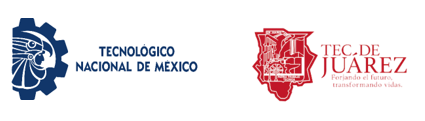

#**INSTITUTO TECNOLOGICO DE CIUDAD JUAREZ**
**Ciencia y analítica de datos**

*   NOMBRE: María Fernanda Delgado Ramírez
*   NO. CONTROL: 23111480

 **UNIDAD 3**

SVD - Sistema de Recomendación

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### **Conexión con Google Drive**

Esta celda conecta Google Drive con Colab para poder leer los archivos de datos que están guardados ahí. Al ejecutarla, Colab pide permiso para acceder a la cuenta y, cuando la conexión se hace correctamente, muestra el mensaje `Mounted at /content/drive`.

In [ ]:
#--------------------------------------------------------------------
# Incluye aquí todas las librerías y paquetes que requieras.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error
import math

#-------------------------------------------------------------------

#Ejercicio
from sklearn.decomposition import TruncatedSVD

### **Librerías utilizadas**

Se importan las herramientas que se usan a lo largo de la actividad:

- `pandas`: para cargar, unir y acomodar los datos en tablas (DataFrames).
- `numpy`: para trabajar con matrices, que es necesario en la factorización SVD y en el cálculo de correlaciones.
- `matplotlib` y `seaborn`: para hacer gráficas.
- `TruncatedSVD` de scikit-learn: para aplicar la factorización SVD reducida, que se usa en los ejercicios 4, 5 y 6.
- `mean_squared_error` y `math`: vienen en la plantilla, pero en esta actividad no se utilizan.

### **Liga de Datos de la UCI "Restaurant & consumer data".**
### **Descarga el archivo "restaurant+consumer+data.zip" y de ahí necesitaremos los archivos "rating_final.csv" y "geoplaces2.csv".**

https://archive.ics.uci.edu/dataset/232/restaurant+consumer+data



In [ ]:
# Descarga los archivos de la página de la UCI a partir de los cuales generaremos
# nuestras matrices de utilidad.

data1 = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Analisis/rating_final.csv", header='infer', sep=",")
data2 = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Analisis/geoplaces2.csv", header='infer',  encoding='latin-1')

print(data1.shape, data2.shape)


(1161, 5) (130, 21)


### **Carga de los datos**

Se leen los dos archivos de la base de datos "Restaurant & consumer data" de la UCI y se guardan en dos tablas:

- `data1` (`rating_final.csv`): contiene las calificaciones que los usuarios dieron a los restaurantes. Tiene 1,161 filas y 5 columnas.
- `data2` (`geoplaces2.csv`): contiene la información de los restaurantes, como su nombre, ubicación y características. Tiene 130 filas y 21 columnas.

El argumento `header='infer'` indica que la primera fila del archivo contiene los nombres de las columnas, y `sep=","` indica que los datos están separados por comas. El uso de `encoding='latin-1'` se explica en el Ejercicio 1.

**NOTA: Recuerda que cada vez que se te pida incluir líneas de código, podrás incluir 1 o más líneas, pero siempre en la sección donde se te indica hacerlo.**

## **Ejercicio - 1**

### **Explica cuál es el propósito de usar el argumento "latin-1" al cargar el segundo archivo.**

Es mas que nada para que al momento de correr la línea no haya problemas, ya que existen algunos archivos antiguos de Windows que contienen letras como la ñ, á, é, í, etc., y se guardan con códigos distintos a los de UTF-8.

Al especificar `latin-1 `, evitamos que el notebook se detenga con un `UnicodeDecodeError` ya seguramos que los nombres de las columnas y los textos se lean correctamente en lugar de mostrar símbolos rotos.


In [ ]:
# Del primer archivo obtenemos una matriz con 3 evaluaciones de los restaurantes:
# general, comida y servicio.
# Las evaluaciones pueden ser 0, 1 o 2, siendo 0 la menor calificación y 2 la
# mayor calificación:
col_eval=['rating', 'food_rating', 'service_rating']
mat_eval=data1[col_eval].astype(int).to_numpy()
print('Dimensión de la matriz de evaluaciones:', mat_eval.shape)

data1.head()

Dimensión de la matriz de evaluaciones: (1161, 3)


,userID,placeID,rating,food_rating,service_rating
0,U1077,135085,2,2,2
1,U1077,135038,2,2,1
2,U1077,132825,2,2,2
3,U1077,135060,1,2,2
4,U1068,135104,1,1,2


### **Matriz de evaluaciones**

Del primer archivo se toman las tres calificaciones que existen: la general (`rating`), la de la comida (`food_rating`) y la del servicio (`service_rating`). Cada una vale 0, 1 o 2, donde 0 es la calificación más baja y 2 la más alta.

La instrucción `astype(int).to_numpy()` convierte estas tres columnas en una matriz de NumPy con valores enteros. Su tamaño es de 1,161 filas por 3 columnas, una fila por cada calificación registrada.

La tabla que se muestra con `data1.head()` presenta las primeras cinco filas. Cada fila indica qué usuario (`userID`) calificó a qué restaurante (`placeID`) y qué calificaciones dio. Por ejemplo, el usuario U1077 calificó con 2 en las tres categorías al restaurante 135085.

In [ ]:
# Del segundo archivo obtenemos información diversa de cada restaurante:
print('Dimensión de data2:', data2.shape)
print('Columnas disponibles:', data2.columns.tolist())

data2.head(2)

Dimensión de data2: (130, 21)
Columnas disponibles: ['placeID', 'latitude', 'longitude', 'the_geom_meter', 'name', 'address', 'city', 'state', 'country', 'fax', 'zip', 'alcohol', 'smoking_area', 'dress_code', 'accessibility', 'price', 'url', 'Rambience', 'franchise', 'area', 'other_services']


,placeID,latitude,longitude,the_geom_meter,name,address,city,state,country,fax,...,alcohol,smoking_area,dress_code,accessibility,price,url,Rambience,franchise,area,other_services
0,134999,18.915421,-99.184871,0101000020957F000088568DE356715AC138C0A525FC46...,Kiku Cuernavaca,Revolucion,Cuernavaca,Morelos,Mexico,?,...,No_Alcohol_Served,none,informal,no_accessibility,medium,kikucuernavaca.com.mx,familiar,f,closed,none
1,132825,22.147392,-100.983092,0101000020957F00001AD016568C4858C1243261274BA5...,puesto de tacos,esquina santos degollado y leon guzman,s.l.p.,s.l.p.,mexico,?,...,No_Alcohol_Served,none,informal,completely,low,?,familiar,f,open,none


### **Información de los restaurantes**

El segundo archivo describe a cada restaurante con 21 columnas, que incluyen su ubicación (`latitude`, `longitude`, `address`, `city`), su nombre (`name`) y algunas características como `alcohol`, `smoking_area`, `dress_code` y `price`.

Para esta actividad solo se necesitan dos de estas columnas: `placeID`, que identifica al restaurante, y `name`, que contiene su nombre.

In [ ]:
# De data1 no requeriremos "rating" y de data2 solo necesitamos "placeID" y "name":
# Definimos la lista y matrices con los factores que necesitamos:
# ************* Inlcuye aquí tu código:*****************************
lista_data1 = ['userID','placeID','food_rating','service_rating']
lista_data2 = ['placeID', 'name']
# *********** Aquí termina la sección de agregar código *************
data1a = data1[lista_data1]
data2a = data2[lista_data2]

In [ ]:
print(data1a.head(2))
print(data2a.head(2))


  userID  placeID  food_rating  service_rating
0  U1077   135085            2               2
1  U1077   135038            2               1
   placeID             name
0   134999  Kiku Cuernavaca
1   132825  puesto de tacos


### **Selección de las columnas necesarias**

Se crean dos listas con las columnas que se van a conservar y con ellas se obtienen dos tablas más pequeñas:

- `data1a`: conserva `userID`, `placeID`, `food_rating` y `service_rating`. Se quita la calificación general (`rating`) porque la actividad trabaja por separado la calificación de la comida y la del servicio.
- `data2a`: conserva solamente `placeID` y `name`.

Las primeras filas de cada tabla muestran que ambas tienen la columna `placeID`. Esa columna en común se usa en el siguiente ejercicio para unirlas.

## **Ejercicio - 2**

In [ ]:
# Define el DataFrame que conjunte la información de las dos DataFrame data1a
# y data2a en uno solo, a través de la columna común "placeID" y que
# llamaremos "df_combinado":

# ************* Inlcuye aquí tu código:*****************************
#utilice  merge()
df_combinado=pd.merge(data1a,data2a, on='placeID')

# *********** Aquí termina la sección de agregar código *************
# Despleguemos la dimensión y los primeros renglones de este DataFrame:

print(df_combinado.shape)
df_combinado.head()

(1161, 5)


,userID,placeID,food_rating,service_rating,name
0,U1077,135085,2,2,Tortas Locas Hipocampo
1,U1077,135038,2,1,Restaurant la Chalita
2,U1077,132825,2,2,puesto de tacos
3,U1077,135060,2,2,Restaurante Marisco Sam
4,U1068,135104,1,2,vips


### **Unión de las dos tablas**

La función `pd.merge(data1a, data2a, on='placeID')` une las dos tablas usando la columna común `placeID`. Con esto, cada calificación queda acompañada del nombre del restaurante al que corresponde, y ya no es necesario recordar su número de identificación.

La nueva tabla, `df_combinado`, tiene 1,161 filas y 5 columnas (`userID`, `placeID`, `food_rating`, `service_rating` y `name`). Como el número de filas es el mismo que el de `data1a`, a todas las calificaciones se les encontró su restaurante.

## **Ejercicio - 3**

In [ ]:
#    Define la matriz de utilidad cuyos renglones sean los nombres de los
#    restaurantes, las columnas los IDs de los usuarios y las entradas la
#    evaluación de la comida (food_rating). La llamaremos "UtMx_food".


# ************* Inlcuye aquí tu código:*****************************


UtMx_food = df_combinado.pivot_table(values="food_rating", index="name", columns="userID", fill_value=0)


# *********** Aquí termina la sección de agregar código *************


print('Dimensión de la matriz de Utilidad sobre la evaluación de la comida:')
print('(restaurantes, usuarios) =', (UtMx_food.shape))
UtMx_food.head()

Dimensión de la matriz de Utilidad sobre la evaluación de la comida:
(restaurantes, usuarios) = (129, 138)


userID,U1001,U1002,U1003,U1004,U1005,U1006,U1007,U1008,U1009,U1010,...,U1129,U1130,U1131,U1132,U1133,U1134,U1135,U1136,U1137,U1138
name,,,,,,,,,,,,,,,,,,,,,
Abondance Restaurante Bar,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Arrachela Grill,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cabana Huasteca,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
Cafe Chaires,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cafeteria cenidet,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### **Matriz de utilidad de la comida**

Una matriz de utilidad es una tabla donde las filas son los elementos que se quieren recomendar (aquí, los restaurantes), las columnas son los usuarios y cada celda contiene la calificación que ese usuario dio a ese elemento.

Para construirla se usa `pivot_table` con estos argumentos:

- `values="food_rating"`: los valores de la tabla son las calificaciones de la comida.
- `index="name"`: cada fila es un restaurante, identificado por su nombre.
- `columns="userID"`: cada columna es un usuario.
- `fill_value=0`: si un usuario no calificó un restaurante, la celda se llena con 0.

El resultado tiene 129 filas y 138 columnas, es decir, 129 restaurantes y 138 usuarios. El archivo de restaurantes tiene 130, pero dos de ellos comparten el mismo nombre ("Gorditas Dona Tota"). Como las filas se forman por nombre, esos dos quedan juntos en una sola fila.

Hay dos cosas importantes de esta matriz. Primero, tiene muy pocos datos: hay 1,161 calificaciones para 17,802 celdas (129 × 138), es decir, solo alrededor del 6.5 % de la tabla tiene una calificación. Segundo, el 0 se usa tanto para "no calificó" como para la calificación más baja, así que el modelo no distingue entre las dos situaciones. Por eso, solo cerca del 5 % de las celdas tiene un valor mayor que 0.

## **Ejercicio - 4**

### **En la Factorización SVD la cantidad de valores singulares será menor o igual al menor valor de los renglones o columnas de la matriz de utilidad UtMx.**

### **La factorización SVD de una matriz $A$ tiene la forma:**

$A_{m\times n} = U_{m\times m}\Sigma_{m\times n}V_{n\times n}^T$

In [ ]:
# a. Aplica la transformación SVD para obtener la matriz de las variables
#    latentes de los restaurantes, en relación a la manera en que los usuarios
#    evaluaron la comida. Deberás obtener la factorización SVD con el máximo número
#    de componentes y por lo tanto el máximo de valores singulares posibles de acuerdo
#    a este criterio. Así, de acuerdo al resultado obtenido en el Ejercicio-3, asigna
#    a la variable "nc_food" el número entero adecuado para llegar a obtener el
#    resultado pedido.


# ************* Inlcuye aquí tu código:**********************************************

#Aplica Factorización SVD
U,s, Vt=np.linalg.svd(UtMx_food,full_matrices=False)
nc_food = min(UtMx_food.shape)    # número de componentes

# *********** Aquí termina la sección de agregar código *****************************

print('Total de valores singulares basados en evaluación de la comida:', nc_food)

Total de valores singulares basados en evaluación de la comida: 129


### **Factorización SVD y número de valores singulares**

La función `np.linalg.svd` descompone la matriz de utilidad en tres matrices: `U`, `s` y `Vt`. De forma sencilla, `U` describe a los restaurantes mediante factores ocultos (variables latentes), `s` indica qué tan importante es cada factor y `Vt` describe a los usuarios con esos mismos factores. El argumento `full_matrices=False` hace que las matrices se obtengan en su tamaño reducido.

El número máximo de valores singulares es el menor entre el número de filas y de columnas de la matriz. Como la matriz tiene 129 filas y 138 columnas, el máximo es 129. Por eso `nc_food = min(UtMx_food.shape)` da como resultado 129, que es el valor que se imprime.

In [ ]:
# b. Lleva a cabo la factorización SVD truncada en la matriz de utilidad
#    obtenida previamente y con respecto al número de componentes dada
#    por la variable nc_food.

# ************* Inlcuye aquí tu código:********************************

SVD_food = TruncatedSVD(n_components=nc_food, random_state=1)
SVD_food.fit_transform(UtMx_food)  #transforma

# *********** Aquí termina la sección de agregar código ***************

# Con la factorización SVD truncada obtenida, determinemos la cantidad
# de componentes que explican un 90% de la variabilidad acumulada de
# cada componente:

for j in range(nc_food):
  if SVD_food.explained_variance_ratio_[0:j].sum() > 0.90:
    break

# Usaremos esta cantidad de componentes para las recomendaciones basadas
# en la calificación de la comida:
N_food = j

print('Valor de truncamiento al 90% de dicha variabilidad:', N_food)

Valor de truncamiento al 90% de dicha variabilidad: 52


### **SVD truncada y varianza explicada**

Aquí se aplica `TruncatedSVD` con 129 componentes (el valor de `nc_food`), que es el máximo posible. Cada componente explica una parte de la variabilidad de los datos, y esa proporción se consulta con `explained_variance_ratio_`.

El ciclo `for` va sumando la proporción de las primeras `j` componentes y se detiene en cuanto la suma supera 0.90, es decir, el 90 % de la variabilidad. Ese valor de `j` se guarda en `N_food` y es 52.

Esto quiere decir que, de las 129 componentes posibles, con 52 ya se conserva más del 90 % de la información. Así se simplifica la matriz sin perder demasiado de lo que dicen los datos, y esas 52 componentes son las que se usan para recomendar.

In [ ]:
# Usando la métrica de correlación de Pearson, obtenemos ahora las 10 mejores
# recomendaciones de este modelo no supervisado con base a la información de
# alguien que desea obtener las similitudes con el "Restaurante Pueblo Bonito"
# y con la cota de truncamiento obtenido en el ejercicio anterior.
# Para ello obtenemos las 10 mejores correlaciones positivas a continuación.

# Factorización SVD:
SVD_food = TruncatedSVD(n_components = N_food, random_state=1)
resultant_matrix_food = SVD_food.fit_transform(UtMx_food)

# Matriz de correlación de Pearson:
corr_mat_food = np.corrcoef(resultant_matrix_food)

# Restaurante de referencia:
restaurante_de_referencia = "Restaurante Pueblo Bonito"
nombres_rest = UtMx_food.T.columns  # nombres de restaurantes
idx_rest = list(nombres_rest).index(restaurante_de_referencia)
corr_rest = corr_mat_food[idx_rest] # Vector de correlación del restaurante de referencia

# Buscando las correlaciones positivas:
idx = (corr_rest>0)
mejores_sim_food = list()
for i in range(len(nombres_rest[idx])):
  mejores_sim_food.append((corr_rest[idx][i], nombres_rest[idx][i]))

print('Total de similaridades positivas encontradas:', len(mejores_sim_food))

print('Algunos de los resultados encontrados:')
mejores_sim_food[0:5]

Total de similaridades positivas encontradas: 63
Algunos de los resultados encontrados:


[(np.float64(0.05094722860823048), 'Cabana Huasteca'),
 (np.float64(0.019442597462500228), 'Cafe Chaires'),
 (np.float64(0.0087959189681921), 'Cafeteria cenidet'),
 (np.float64(0.2462332354480614), 'Cafeteria y Restaurant El Pacifico'),
 (np.float64(0.021013163295722708), 'Cenaduria El RincÃ³n de Tlaquepaque')]

### **Similitud entre restaurantes con la correlación de Pearson**

En esta celda se obtienen los restaurantes más parecidos al "Restaurante Pueblo Bonito" según las calificaciones de la comida. Los pasos son:

1. Se aplica la SVD con 52 componentes. El resultado, `resultant_matrix_food`, describe a cada restaurante con 52 valores en lugar de 138 (uno por usuario). El argumento `random_state=1` hace que el resultado sea el mismo cada vez que se ejecuta la celda.
2. Con `np.corrcoef` se calcula la correlación de Pearson entre todos los restaurantes. El resultado es una matriz de 129 por 129 en la que un valor cercano a 1 indica restaurantes muy parecidos, un valor cercano a 0 indica que no hay relación, y un valor negativo indica comportamientos opuestos.
3. Se busca la posición del restaurante de referencia y se toma su fila de la matriz, es decir, su correlación con todos los demás.
4. Se conservan solo las correlaciones positivas y se guardan en la lista `mejores_sim_food`, con el formato (correlación, nombre).

Se encontraron 63 restaurantes con una similitud positiva. Los primeros cinco de la lista tienen valores bajos, entre 0.009 y 0.25. Esto ocurre porque la lista sigue el orden de la matriz y no el de la similitud. Por eso se ordena en el siguiente ejercicio.

## **Ejercicio - 5**

In [ ]:
# Ordenar la lista de recomendaciones "mejores_sim_food" encontrada en el paso
# anterior de manera descendente. Llamaremos "mejores_sim_food_ordenadas" a
# dicha lista.

mejores_sim_food_ordenadas = sorted(mejores_sim_food, key=lambda simil: simil[0], reverse=True)

# Desplegamos las 10 mejores similitudes encontradas de manera descendente:
print('Similitudes con base a la evaluación de la comida con mayores valores de correlación:')
for k in range(1,11):
  print('%d> %s' % (k, mejores_sim_food_ordenadas[k]))

Similitudes con base a la evaluación de la comida con mayores valores de correlación:
1> (np.float64(0.756935091169195), 'Restaurante la Estrella de Dima')
2> (np.float64(0.7024759678276519), 'pizza clasica')
3> (np.float64(0.6576625964860859), 'Restaurante Guerra')
4> (np.float64(0.5368481586199824), 'El Club')
5> (np.float64(0.3723010790223296), 'Pizzeria Julios')
6> (np.float64(0.32793722637276057), 'Hamburguesas saul')
7> (np.float64(0.3005926323476231), 'La Fontana Pizza Restaurante and Cafe')
8> (np.float64(0.2946844364632474), 'Restaurant Oriental Express')
9> (np.float64(0.29450534066755935), 'la Cochinita Pibil Restaurante Yucateco')
10> (np.float64(0.29331166939160924), 'Restaurante El Cielo Potosino')


### **Las 10 mejores recomendaciones según la comida**

La función `sorted` ordena la lista de mayor a menor correlación, usando `key=lambda simil: simil[0]` para indicar que se ordena por el primer elemento de cada pareja, que es la correlación. Después se imprimen los lugares del 1 al 10. El ciclo empieza en la posición 1 porque en la posición 0 queda el propio Pueblo Bonito, que tiene una correlación de 1 consigo mismo y no se debe recomendar.

Los restaurantes más parecidos en cuanto a la comida son Restaurante la Estrella de Dima (0.76), pizza clasica (0.70), Restaurante Guerra (0.66) y El Club (0.54). Estos cuatro tienen una correlación mayor a 0.5. Del quinto al décimo lugar, la correlación baja de 0.37 a 0.29.

## **Ejercicio - 6**

### **De manera análoga y usando ahora la evaluación de un restaurante con respecto a su servicio (service_rating), encuentra ahora los diez restaurantes con mayor similaridad al mismo restaurante anterior llamado "Restaurante Pueblo Bonito" y con respecto también a la misma métrica de similaridad de Pearson.**

### **Deberás usar la cantidad de componentes necesarias para que la varabilidad de la factorización SVD quede explicada en un 90%.**

### **a.  Para ello define primero la matriz de utilidad, UtMx_service, donde los renglones son los nombres de los restaurantes, las columnas los usuarios y las entradas las evaluaciones con respecto al servicio recibido en el restaurante.**





In [ ]:
# a. Define la matriz de utilidad cuyos renglones sean los nombres de los
#    restaurantes, las columnas los IDs de los usuarios y las entradas la
#    evaluación del servicio (service_rating). La llamaremos "UtMx_service".

# ************* Inlcuye aquí tu código:*****************************

UtMx_service = df_combinado.pivot_table(values="service_rating", index="name", columns="userID", fill_value=0)

# *********** Aquí termina la sección de agregar código *************

print('Dimensión de la matriz de Utilidad sobre la evaluación del servicio:')
print('(restaurantes, usuarios) =', (UtMx_service.shape))
UtMx_service.head()

Dimensión de la matriz de Utilidad sobre la evaluación del servicio:
(restaurantes, usuarios) = (129, 138)


userID,U1001,U1002,U1003,U1004,U1005,U1006,U1007,U1008,U1009,U1010,...,U1129,U1130,U1131,U1132,U1133,U1134,U1135,U1136,U1137,U1138
name,,,,,,,,,,,,,,,,,,,,,
Abondance Restaurante Bar,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Arrachela Grill,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cabana Huasteca,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
Cafe Chaires,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cafeteria cenidet,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### **Matriz de utilidad del servicio**

Se repite el procedimiento del Ejercicio 3, pero ahora los valores de la tabla son las calificaciones del servicio (`service_rating`). La matriz queda del mismo tamaño que la de la comida (129 restaurantes por 138 usuarios), porque se trata de los mismos restaurantes y usuarios. Lo único que cambia es la calificación que contiene cada celda.

In [ ]:
# b. Incluye el código necesario para obtener y desplegar los 10 restaurantes con
#    mayor similaridad de Pearson al "Restaurante Pueblo Bonito", y usando solo
#    el 90% de las componentes que explican la varianza de la matriz UtMx_service.
#    Desplegarlos en orden descendente, sin incliur el restaurante de referencia.

# ************* Inlcuye aquí tu código:*****************************
 # Incluye todas las líneas de código o celdas que requieras.

total_componentes = min(UtMx_service.shape) - 1
svd_full = TruncatedSVD(n_components=total_componentes, random_state=42)
svd_full.fit(UtMx_service)

# 2. Calcular cuántas componentes explican al menos el 90% de la varianza acumulada
varianza_acumulada = np.cumsum(svd_full.explained_variance_ratio_)
n_comp_90 = np.argmax(varianza_acumulada >= 0.90) + 1

print("Total Valores Singulares. Evaluación Servicio:  ", total_componentes + 1)
print("\nValor Truncamiento 90% de dicha variabilidad: ", n_comp_90)

# 3. Aplicar TruncatedSVD con las componentes que cubren el 90% de la varianza
svd = TruncatedSVD(n_components=n_comp_90, random_state=42)
matriz_reducida = svd.fit_transform(UtMx_service)

# 4. Calcular la matriz de correlación de Pearson sobre la matriz reducida
corr_mat = np.corrcoef(matriz_reducida)

restaurante_de_referencia = "Restaurante Pueblo Bonito"
nombres_restaurantes = list(UtMx_service.index)
index_rest = list(UtMx_service.T.columns).index(restaurante_de_referencia)
corr_rest = corr_mat[index_rest]

index_ord=np.argsort(corr_rest)[::-1]

mejores_idx = [idx for idx in index_ord
               if idx != index_rest and corr_rest[idx] > 0]

print("\n\nTotal Similidad Positiva Encontrada: ", len(mejores_idx))
print("\n\nSimulitud en base a Evalucación Servicio con mayor valor Correlación: ")

# 8. Desplegar el Top 10 en orden descendente
for i, idx in enumerate(mejores_idx[:10], start=1):
    print(f"{i} > ({corr_rest[idx]}, '{nombres_restaurantes[idx]}')")

# *********** Aquí termina la sección de agregar código *************

Total Valores Singulares. Evaluación Servicio:   129

Valor Truncamiento 90% de dicha variabilidad:  52


Total Similidad Positiva Encontrada:  55


Simulitud en base a Evalucación Servicio con mayor valor Correlación: 
1 > (0.6626594505707143, 'pizza clasica')
2 > (0.5793478698681568, 'El Club')
3 > (0.4784564887343928, 'Restaurante la Estrella de Dima')
4 > (0.47577491552582624, 'Hamburguesas saul')
5 > (0.42858575978917074, 'Restaurante Guerra')
6 > (0.41382967220324496, 'Restaurant Orizatlan')
7 > (0.36057904679684744, 'la Cochinita Pibil Restaurante Yucateco')
8 > (0.3501235584252351, 'Restaurante El Cielo Potosino')
9 > (0.31457832381462325, 'La Fontana Pizza Restaurante and Cafe')
10 > (0.30082084628345745, 'puesto de tacos')


### **Recomendaciones según el servicio**

Esta celda repite el proceso completo de la comida, pero con la matriz del servicio. Los pasos son:

1. Se ajusta una SVD truncada con 128 componentes (el máximo posible menos uno) y se imprime el total de valores singulares, que es 129.
2. Con `np.cumsum` se calcula la varianza acumulada y se busca el primer número de componentes que llega al 90 %. El resultado es 52.
3. Se aplica de nuevo la SVD con esas 52 componentes y se obtiene la matriz reducida de los restaurantes.
4. Se calcula la matriz de correlación de Pearson y se toma la fila del "Restaurante Pueblo Bonito".
5. Con `np.argsort` se ordenan los restaurantes de mayor a menor correlación. Se descarta el restaurante de referencia y se conservan solo las correlaciones positivas, de las que se encontraron 55.
6. Se imprimen los 10 primeros.

Según el servicio, los restaurantes más parecidos son pizza clasica (0.66), El Club (0.58), Restaurante la Estrella de Dima (0.48), Hamburguesas saul (0.48) y Restaurante Guerra (0.43). El décimo lugar es puesto de tacos, con 0.30.

El número de componentes para el 90 % es el mismo que se obtuvo con la comida (52).

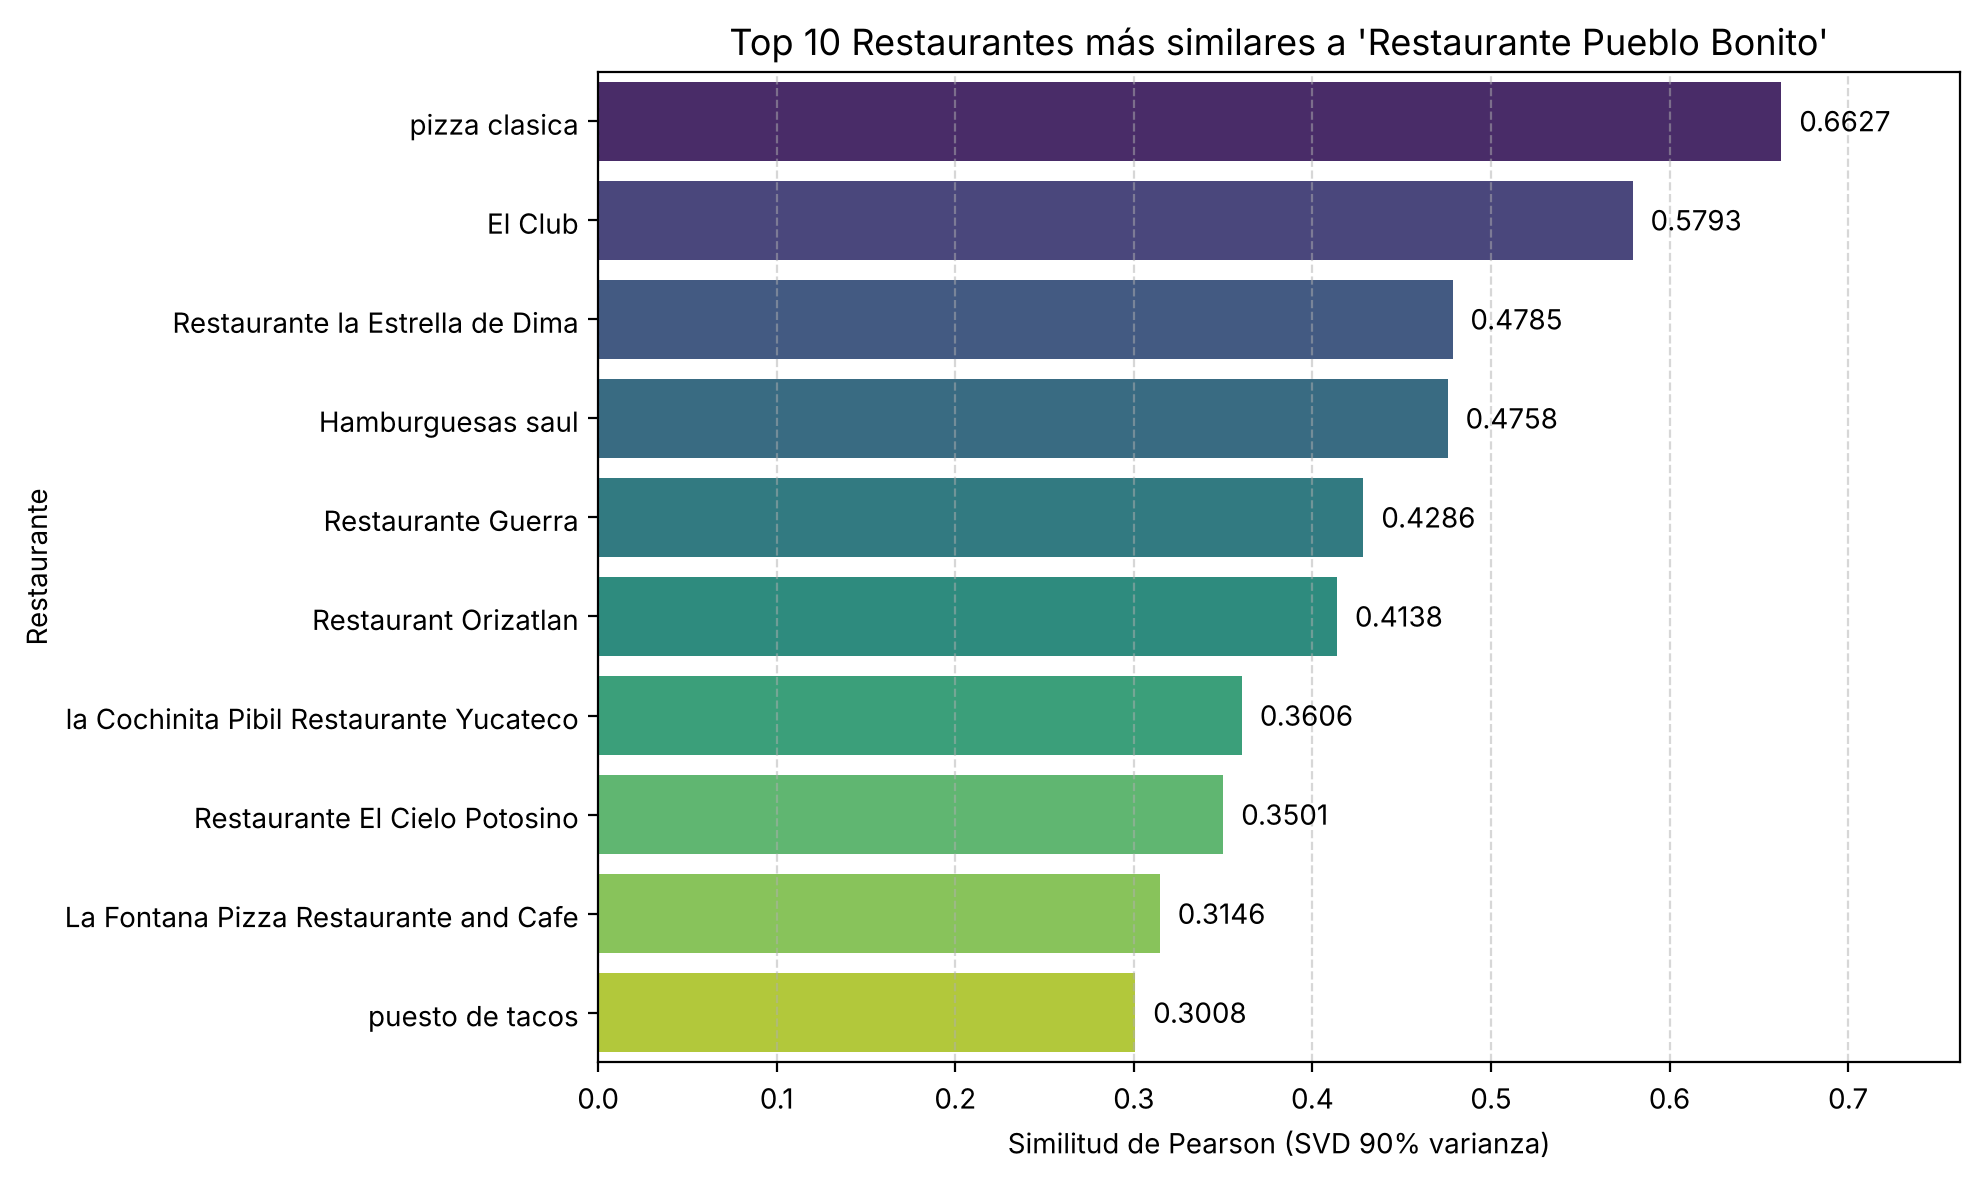

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extraer los nombres y valores del Top 10 ya calculados
top_10_idx = mejores_idx[:10]
nombres_top10 = [nombres_restaurantes[i] for i in top_10_idx]
valores_top10 = [corr_rest[i] for i in top_10_idx]

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=valores_top10, y=nombres_top10, hue=nombres_top10, palette="viridis", legend=False)

# Añadir el valor numérico al final de cada barra
for i, v in enumerate(valores_top10):
    ax.text(v + 0.01, i, f"{v:.4f}", va="center", fontsize=10)

plt.title(f"Top 10 Restaurantes más similares a '{restaurante_de_referencia}'", fontsize=13)
plt.xlabel("Similitud de Pearson (SVD 90% varianza)")
plt.ylabel("Restaurante")
plt.xlim(0, max(valores_top10) + 0.1)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### **Gráfica del Top 10 por servicio**

Esta gráfica muestra los resultados anteriores en barras horizontales. Se reutilizan los nombres y las correlaciones del Top 10 ya calculados. Cada barra representa un restaurante y su longitud indica qué tan parecido es al "Restaurante Pueblo Bonito" según la calificación del servicio: entre más larga es la barra, mayor es la similitud. Al final de cada barra se escribe el valor exacto de la correlación y el eje horizontal empieza en 0, ya que solo se muestran correlaciones positivas.

## **Ejercicio - 7**

### **Incluye tus comentarios y conclusiones de la actividad. En particular indica cuáles restaurantes encontraste con correlaciones altas tanto para la calificación de la comida, como del servicio.**

###**Conclusión**

En esta actividad se construyó un sistema de recomendación de restaurantes a partir de las calificaciones de comida y servicio dadas por 138 usuarios. Primero se armó una matriz de utilidad para cada calificación (129 restaurantes por 138 usuarios). Después se aplicó la factorización SVD para resumir cada matriz en 52 variables latentes, que conservan más del 90 % de la variabilidad. Por último, se calculó la correlación de Pearson entre restaurantes para encontrar cuáles se parecen más al "Restaurante Pueblo Bonito".

Los resultados cambian un poco según lo que se evalúe. Para la comida, los más parecidos fueron Restaurante la Estrella de Dima (0.757), pizza clasica (0.702) y Restaurante Guerra (0.658). Para el servicio, los primeros lugares fueron pizza clasica (0.663), El Club (0.579) y Restaurante la Estrella de Dima (0.478).


###**Restaurantes identificados con Correlación Alta con Restaurante Pueblo Bonito**

Ocho restaurantes aparecen en los diez primeros lugares de las dos listas, es decir, se parecen a Pueblo Bonito tanto en comida como en servicio. La tabla está ordenada por el promedio de las dos correlaciones:

| # | Nombre | Correlación Comida | Correlación Servicio | Promedio |
|--------|------------------------|-----------------------|---------------------|----------|
| 1 | pizza clasica | 0.702 | 0.663 | 0.683 |
| 2 | Restaurante la Estrella de Dima | 0.757 | 0.478 | 0.618 |
| 3 | El Club | 0.537 | 0.579 | 0.558 |
| 4 | Restaurante Guerra | 0.658 | 0.429 | 0.543 |
| 5 | Hamburguesas saul | 0.328 | 0.476 | 0.402 |
| 6 | la Cochinita Pibil Restaurante Yucateco | 0.295 | 0.361 | 0.328 |
| 7 | Restaurante El Cielo Potosino | 0.293 | 0.350 | 0.322 |
| 8 | La Fontana Pizza Restaurante and Cafe | 0.301 | 0.315 | 0.308 |


- **pizza clasica** tiene el mejor promedio (0.683) y es el único con una correlación mayor a 0.65 tanto en comida como en servicio.
- **Restaurante la Estrella de Dima, El Club y Restaurante Guerra** también tienen correlaciones mayores a 0.4 en comida y en servicio, por lo que se pueden considerar buenas recomendaciones junto con pizza clasica.
- **Hamburguesas saul, la Cochinita Pibil Restaurante Yucateco, Restaurante El Cielo Potosino y La Fontana Pizza Restaurante and Cafe** aparecen en ambas listas, pero con correlaciones más bajas, con promedios de alrededor de 0.3 a 0.4.
- Algunos restaurantes solo aparecen en una de las listas: Pizzeria Julios (0.372) y Restaurant Oriental Express (0.295) en comida, y Restaurant Orizatlan (0.414) y puesto de tacos (0.301) en servicio.

###**Observaciones**

- La matriz de utilidad tiene muy pocos datos: solo cerca del 5 % de sus celdas tiene una calificación mayor que 0, y los lugares sin calificación se llenaron con 0, que también es una calificación real. Por eso, los resultados son una aproximación y no una medida exacta del gusto de los usuarios.
- Dos restaurantes con el mismo nombre ("Gorditas Dona Tota") quedaron juntos en una sola fila de la matriz, por eso hay 129 filas y no 130.
- Si una persona disfrutó el Restaurante Pueblo Bonito, las recomendaciones más sólidas del sistema serían pizza clasica, Restaurante la Estrella de Dima, El Club, Restaurante Guerra.


>> **Fin de la Actividad de Sistemas de Recomendación**